# 05 - Labels (landslide inventory)

**Purpose:** Load the NBRO landslide inventory (head-scarp centroid points) for all four districts, label as positive (1). Generate an equal or larger number of non-landslide points (label 0) by random sampling outside a buffer around known landslides. Save as `data/processed/labels.parquet` (GeoParquet).

In [2]:
import sys
from pathlib import Path

import geopandas as gpd
import pandas as pd
import numpy as np
from shapely.geometry import Point
import matplotlib.pyplot as plt

sys.path.append("../src")
from landslide_lk import geo_utils

DATA_RAW = Path("../data/raw")
DATA_PROCESSED = Path("../data/processed")

In [2]:
aoi_path = DATA_PROCESSED / "aoi.gpkg"
assert aoi_path.exists(), "aoi.gpkg missing — run notebook 01 first"

aoi = gpd.read_file(aoi_path, layer="dissolved")
aoi_wgs84 = aoi.to_crs("EPSG:4326")  # OpenTopography API wants lat/lon

minx, miny, maxx, maxy = aoi_wgs84.total_bounds
print(f"Bounding box: {minx:.4f}, {miny:.4f}, {maxx:.4f}, {maxy:.4f}")

Bounding box: 79.8863, 6.2288, 81.2715, 7.6216


In [4]:
import requests
import geopandas as gpd

url = "https://gis.earthdata.nasa.gov/gis05/rest/services/Landslides/COOLR_Events_Points/FeatureServer/0/query"
params = {
    "where": "1=1",
    "outFields": "*",
    "f": "geojson",
    "geometry": f"{minx},{miny},{maxx},{maxy}",  # your AOI bounding box from earlier
    "geometryType": "esriGeometryEnvelope",
    "inSR": "4326",
    "spatialRel": "esriSpatialRelIntersects",
}
r = requests.get(url, params=params, timeout=30)
r.raise_for_status()

coolr = gpd.GeoDataFrame.from_features(r.json()["features"], crs="EPSG:4326")
print(f"{len(coolr)} COOLR points in AOI bounding box")
coolr.to_file(DATA_RAW / "coolr_landslides.gpkg", driver="GPKG")

ReadTimeout: HTTPSConnectionPool(host='gis.earthdata.nasa.gov', port=443): Read timed out. (read timeout=30)

In [3]:
import requests
import geopandas as gpd
import time

url = "https://gis.earthdata.nasa.gov/gis05/rest/services/Landslides/COOLR_Events_Points/FeatureServer/0/query"
params = {
    "where": "1=1",
    "outFields": "*",
    "f": "geojson",
    "geometry": f"{minx},{miny},{maxx},{maxy}",
    "geometryType": "esriGeometryEnvelope",
    "inSR": "4326",
    "spatialRel": "esriSpatialRelIntersects",
}

r = None
for attempt in range(4):
    try:
        r = requests.get(url, params=params, timeout=90)  # generous timeout
        r.raise_for_status()
        break
    except requests.exceptions.RequestException as e:
        wait = 10 * (attempt + 1)
        print(f"Attempt {attempt+1} failed ({e}); retrying in {wait}s...")
        time.sleep(wait)

assert r is not None and r.status_code == 200, "COOLR query failed after retries"
print("Status:", r.status_code)

Status: 200


In [4]:
data = r.json()
print(list(data.keys()))

if "error" in data:
    print("API returned an error:", data["error"])
else:
    print(f"{len(data.get('features', []))} features returned")

['type', 'features']
0 features returned


In [5]:
url = "https://gis.earthdata.nasa.gov/gis05/rest/services/Landslides/COOLR_Reports_Points/FeatureServer/0/query"
params = {
    "where": "1=1",
    "outFields": "*",
    "f": "geojson",
    "geometry": f"{minx},{miny},{maxx},{maxy}",
    "geometryType": "esriGeometryEnvelope",
    "inSR": "4326",
    "spatialRel": "esriSpatialRelIntersects",
}

r = None
for attempt in range(4):
    try:
        r = requests.get(url, params=params, timeout=90)
        r.raise_for_status()
        break
    except requests.exceptions.RequestException as e:
        wait = 10 * (attempt + 1)
        print(f"Attempt {attempt+1} failed ({e}); retrying in {wait}s...")
        time.sleep(wait)

data = r.json()
print(f"{len(data.get('features', []))} features returned")

83 features returned


In [6]:
coolr = gpd.GeoDataFrame.from_features(data["features"], crs="EPSG:4326")
print(f"{len(coolr)} COOLR points in bounding box")
print(coolr.columns.tolist())

83 COOLR points in bounding box
['geometry', 'objectid', 'source_name', 'source_link', 'event_id', 'event_date', 'event_time', 'event_title', 'event_description', 'location_description', 'location_accuracy', 'landslide_category', 'landslide_trigger', 'landslide_size', 'landslide_setting', 'fatality_count', 'injury_count', 'storm_name', 'photo_link', 'comments', 'event_import_source', 'event_import_id', 'latitude', 'longitude', 'country_name', 'country_code', 'admin_division_name', 'gazetteer_closest_point', 'gazetteer_distance', 'submitted_date', 'last_edited_date']


In [8]:
aoi = gpd.read_file(DATA_PROCESSED / "aoi.gpkg", layer="districts")
aoi_dissolved = gpd.read_file(DATA_PROCESSED / "aoi.gpkg", layer="dissolved")
aoi_utm = aoi.to_crs("EPSG:32644")
aoi_dissolved_utm = aoi_dissolved.to_crs("EPSG:32644")

print(aoi_utm.crs, len(aoi_utm))

EPSG:32644 6


In [9]:
coolr_utm = coolr.to_crs("EPSG:32644")
coolr_in_aoi = coolr_utm[coolr_utm.within(aoi_dissolved_utm.geometry.iloc[0])].reset_index(drop=True)
print(f"{len(coolr_in_aoi)} points within the six-district AOI (vs {len(coolr)} in the bounding box)")

71 points within the six-district AOI (vs 83 in the bounding box)


In [ ]:
coolr_in_aoi.to_file(DATA_RAW / "coolr_landslides.gpkg", driver="GPKG")

#  checking date range and source
print(coolr_in_aoi[["event_date", "event_import_source"]].head(10) if "event_date" in coolr_in_aoi.columns else coolr_in_aoi.head())

      event_date event_import_source
0  1419552000000                 GLC
1  1367625600000                 GLC
2  1419552000000                 GLC
3  1296518400000                 GLC
4  1443139200000                 GLC
5  1297036800000                 GLC
6  1419552000000                 GLC
7  1209340800000                 GLC
8  1401663600000                 GLC
9  1414567800000                 GLC


In [12]:
# Converting them to actual dates
coolr_in_aoi["event_date_parsed"] = pd.to_datetime(coolr_in_aoi["event_date"], unit="ms")
print(coolr_in_aoi[["event_date_parsed", "event_import_source"]].head(10))

    event_date_parsed event_import_source
0 2014-12-26 00:00:00                 GLC
1 2013-05-04 00:00:00                 GLC
2 2014-12-26 00:00:00                 GLC
3 2011-02-01 00:00:00                 GLC
4 2015-09-25 00:00:00                 GLC
5 2011-02-07 00:00:00                 GLC
6 2014-12-26 00:00:00                 GLC
7 2008-04-28 00:00:00                 GLC
8 2014-06-01 23:00:00                 GLC
9 2014-10-29 07:30:00                 GLC


In [13]:
print(coolr_in_aoi["event_import_source"].value_counts())
print(f"\nDate range: {coolr_in_aoi['event_date_parsed'].min()} to {coolr_in_aoi['event_date_parsed'].max()}")

event_import_source
GLC    71
Name: count, dtype: int64

Date range: 2007-01-13 00:00:00 to 2018-10-13 22:00:47


In [14]:
coolr_in_aoi["event_date"] = coolr_in_aoi["event_date_parsed"]
coolr_in_aoi = coolr_in_aoi.drop(columns="event_date_parsed")

In [15]:
pd.set_option("display.max_rows", None)
print(coolr_in_aoi[["event_date", "event_import_source"]])
pd.reset_option("display.max_rows")  

            event_date event_import_source
0  2014-12-26 00:00:00                 GLC
1  2013-05-04 00:00:00                 GLC
2  2014-12-26 00:00:00                 GLC
3  2011-02-01 00:00:00                 GLC
4  2015-09-25 00:00:00                 GLC
5  2011-02-07 00:00:00                 GLC
6  2014-12-26 00:00:00                 GLC
7  2008-04-28 00:00:00                 GLC
8  2014-06-01 23:00:00                 GLC
9  2014-10-29 07:30:00                 GLC
10 2011-02-01 23:00:00                 GLC
11 2011-01-06 18:00:00                 GLC
12 2018-05-21 00:00:00                 GLC
13 2011-01-09 00:00:00                 GLC
14 2018-10-07 21:07:19                 GLC
15 2014-06-01 23:00:00                 GLC
16 2011-02-23 00:00:00                 GLC
17 2010-10-03 00:00:00                 GLC
18 2007-01-13 00:00:00                 GLC
19 2011-04-23 00:00:00                 GLC
20 2018-10-13 22:00:47                 GLC
21 2017-05-26 00:00:00                 GLC
22 2018-06-

In [16]:
print(coolr_in_aoi.columns.tolist())  # see what's actually available first

['geometry', 'objectid', 'source_name', 'source_link', 'event_id', 'event_date', 'event_time', 'event_title', 'event_description', 'location_description', 'location_accuracy', 'landslide_category', 'landslide_trigger', 'landslide_size', 'landslide_setting', 'fatality_count', 'injury_count', 'storm_name', 'photo_link', 'comments', 'event_import_source', 'event_import_id', 'latitude', 'longitude', 'country_name', 'country_code', 'admin_division_name', 'gazetteer_closest_point', 'gazetteer_distance', 'submitted_date', 'last_edited_date']


In [17]:
pd.set_option("display.max_columns", None)
coolr_in_aoi.head(20)
pd.reset_option("display.max_columns")

In [18]:
# Save a CSV preview for easy inspection in Excel or VS Code
coolr_in_aoi.drop(columns="geometry").to_csv(DATA_RAW / "coolr_preview.csv", index=False)
print("Saved — open this in Excel or VS Code's built-in CSV viewer")

Saved — open this in Excel or VS Code's built-in CSV viewer


In [4]:
# Re-load AOI
aoi = gpd.read_file(DATA_PROCESSED / "aoi.gpkg", layer="districts")
aoi_dissolved = gpd.read_file(DATA_PROCESSED / "aoi.gpkg", layer="dissolved")
aoi_utm = aoi.to_crs("EPSG:32644")
aoi_dissolved_utm = aoi_dissolved.to_crs("EPSG:32644")
print(f"{len(aoi_utm)} districts loaded")

6 districts loaded


In [5]:
# load COOLR, filter to usable location accuracy
usable = pd.read_csv(DATA_RAW / "coolr_preview.csv")
usable = usable[usable["location_accuracy"].isin(["exact", "1km", "5km"])].copy()
print(f"{len(usable)} points with usable location accuracy")

landslides = gpd.GeoDataFrame(
    usable,
    geometry=gpd.points_from_xy(usable["longitude"], usable["latitude"]),
    crs="EPSG:4326",
).to_crs("EPSG:32644")

landslides["label"] = 1
landslides["source"] = "COOLR"
landslides = landslides[landslides.within(aoi_dissolved_utm.geometry.iloc[0])].reset_index(drop=True)
print(f"{len(landslides)} landslide points within the six-district AOI")

39 points with usable location accuracy
39 landslide points within the six-district AOI


In [6]:
#assign each point to its district
landslides = gpd.sjoin(
    landslides, aoi_utm[["adm2_name", "adm2_pcode", "geometry"]], how="left", predicate="within"
).drop(columns="index_right")
print(landslides["adm2_name"].value_counts())

adm2_name
Badulla         16
Nuwara Eliya     8
Kalutara         6
Kegalle          5
Kandy            4
Name: count, dtype: int64


In [7]:
# generate non-landslide (negative) points
N_NEGATIVE = len(landslides)
BUFFER_METERS = 500
rng = np.random.default_rng(42)

buffer_union = landslides.geometry.buffer(BUFFER_METERS).unary_union
valid_area = aoi_dissolved_utm.geometry.iloc[0].difference(buffer_union)
minx, miny, maxx, maxy = valid_area.bounds

negatives = []
attempts = 0
max_attempts = N_NEGATIVE * 100
while len(negatives) < N_NEGATIVE and attempts < max_attempts:
    pt = Point(rng.uniform(minx, maxx), rng.uniform(miny, maxy))
    if valid_area.contains(pt):
        negatives.append(pt)
    attempts += 1

print(f"Generated {len(negatives)} negative points in {attempts} attempts")
assert len(negatives) == N_NEGATIVE, "Could not generate enough negative points"

n = len(negatives)
negatives_gdf = gpd.GeoDataFrame(
    {"label": [0] * n, "source": ["random_sample"] * n},
    geometry=negatives,
    crs="EPSG:32644",
)
negatives_gdf = gpd.sjoin(
    negatives_gdf, aoi_utm[["adm2_name", "adm2_pcode", "geometry"]], how="left", predicate="within"
).drop(columns="index_right")

Generated 39 negative points in 64 attempts


C:\Users\PCC\AppData\Local\Temp\ipykernel_2876\2831889772.py:6: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  buffer_union = landslides.geometry.buffer(BUFFER_METERS).unary_union


In [8]:
#  combine and save
labels = pd.concat([
    landslides[["geometry", "label", "source", "adm2_name", "adm2_pcode"]],
    negatives_gdf[["geometry", "label", "source", "adm2_name", "adm2_pcode"]],
], ignore_index=True)
labels = gpd.GeoDataFrame(labels, crs="EPSG:32644")

out_path = DATA_PROCESSED / "labels.parquet"
labels.to_parquet(out_path)

print(f"Saved {len(labels)} total points: {labels['label'].sum()} landslide, {(labels['label']==0).sum()} non-landslide")
print(labels.groupby(["adm2_name", "label"]).size().unstack(fill_value=0))

Saved 78 total points: 39 landslide, 39 non-landslide
label          0   1
adm2_name           
Badulla        9  16
Kalutara       2   6
Kandy         11   4
Kegalle        4   5
Nuwara Eliya   3   8
Ratnapura     10   0


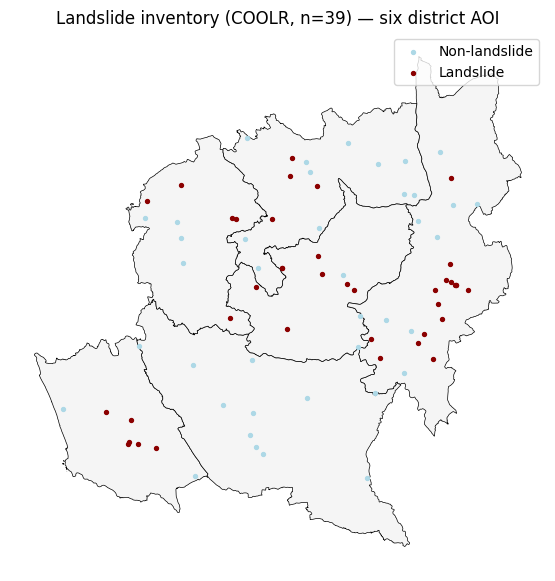

In [9]:
#  visualize
fig, ax = plt.subplots(figsize=(7, 7))
aoi_utm.plot(ax=ax, color="whitesmoke", edgecolor="black", linewidth=0.5)
labels[labels["label"] == 0].plot(ax=ax, color="lightblue", markersize=8, label="Non-landslide")
labels[labels["label"] == 1].plot(ax=ax, color="darkred", markersize=8, label="Landslide")
ax.legend()
ax.set_title(f"Landslide inventory (COOLR, n={labels['label'].sum()}) — six district AOI")
ax.axis("off")
plt.show()

## TODO

Start here — see the purpose note above and the corresponding section of `docs/data_sources.md`.